In [30]:
%pip install numpy scipy pandas matplotlib seaborn scikit-learn jupyter mne


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [31]:
import numpy, scipy, pandas, matplotlib, seaborn, sklearn, mne, jupyter
print("Todo OK")

# TETHA = ESTADO DE CALMA 
# GAMA = PENSAMIENTO ACTIVO (CONCENTRACIÓN)
# NUMEROS IMPARES HEMISFERIO IZQUIERDO
# NUMEROS PARES HEMISFERIO DERECHO

Todo OK


In [32]:
import mne 
ruta_set = "./AD-sub-036_task-eyesclosed_eeg.set"
ruta_edf = "./AD.edf"

# importar los registros
raw_set =mne.io.read_raw_eeglab(ruta_set, preload=False)
raw_edf = mne.io.read_raw_edf(ruta_edf, preload=False)

Reading /home/meme/Documentos/AI_Course/Introduccion_Machine_Learning/notebooks/Señales EEG/AD-sub-036_task-eyesclosed_eeg.set
Extracting EDF parameters from ./AD.edf...
Setting channel info structure...
Creating raw.info structure...


/tmp/ipykernel_57724/1801148919.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_set =mne.io.read_raw_eeglab(ruta_set, preload=False)


In [33]:
# informacion superficial, se esta leyendo que tiene el archivo y cual es su nombre
print('Información del archivo .set:')
print(raw_set)
print('\nInformación del archivo .edf:')
print(raw_edf)

Información del archivo .set:
<RawEEGLAB | AD-sub-036_task-eyesclosed_eeg.set, 19 x 420680 (841.4 s), ~26 KiB, data not loaded>

Información del archivo .edf:
<RawEDF | AD.edf, 30 x 308224 (301.0 s), ~27 KiB, data not loaded>


In [34]:
def consultar_info(raw, nombre):
    print(f"\n{'=' * 40}")
    print(f"INFORMACIÓN DEL ARCHIVO: {nombre}")
    print(f"{'=' * 40}")

    print(f"Número de canales: {len(raw.ch_names)}")
    print(f"Frecuencia de muestreo: {raw.info['sfreq']} Hz")
    print(f"Número de muestras: {raw.n_times}")
    print(f"Duración: {raw.n_times / raw.info['sfreq']:.2f} segundos")
    print(f"Nombres de los canales: {raw.ch_names}")
    print(f"Fecha de medición: {raw.info['meas_date']}")

    print("\nInformación detallada:")
    print(raw.info)

consultar_info(raw_set, "SET")
consultar_info(raw_edf, "EDF")


INFORMACIÓN DEL ARCHIVO: SET
Número de canales: 19
Frecuencia de muestreo: 500.0 Hz
Número de muestras: 420680
Duración: 841.36 segundos
Nombres de los canales: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']
Fecha de medición: None

Información detallada:
<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, ...
 chs: 19 EEG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: unspecified
 nchan: 19
 projs: []
 sfreq: 500.0 Hz
>

INFORMACIÓN DEL ARCHIVO: EDF
Número de canales: 30
Frecuencia de muestreo: 1024.0 Hz
Número de muestras: 308224
Duración: 301.00 segundos
Nombres de los canales: ['Fp1', 'F7', 'F8', 'T4', 'T6', 'T5', 'T3', 'Fp2', 'O1', 'P3', 'Pz', 'F3', 'Fz', 'F4', 'C4', 'P4', 'POz', 'C3', 'Cz', 'O2', 'ECG', 'AUX1', 'AUX2', 'AUX3', 'ESUTimestamp', 'SystemTimestamp', 'Battery', 'Tilt X', 'Tilt Y

In [35]:
# aqui esta mostrando los canles de los archivos .set y .edf, pero solo los primeros 20 canales del archivo .edf
canales = raw_edf.ch_names[:20]
print(f'Canales del archivo .edf: \n{canales}')

Canales del archivo .edf: 
['Fp1', 'F7', 'F8', 'T4', 'T6', 'T5', 'T3', 'Fp2', 'O1', 'P3', 'Pz', 'F3', 'Fz', 'F4', 'C4', 'P4', 'POz', 'C3', 'Cz', 'O2']


In [36]:
# Seleccionar los primeros 20 canales del SET
raw_set_eeg = raw_set.copy()

# Mostrar dimensiones: muestras × canales
print(f"Archivo SET (EEG): {raw_set_eeg.n_times} rows x {len(raw_set_eeg.ch_names)} columns")

# Mostrar nombres de los canales
print("Canales seleccionados:", raw_set_eeg.ch_names)

# Seleccionar los primeros 20 canales del EDF
raw_edf_eeg = raw_edf.copy().pick(raw_edf.ch_names[:20])

# Mostrar dimensiones: muestras × canales
print(f"\nArchivo EDF (EEG): {raw_edf_eeg.n_times} rows x {len(raw_edf_eeg.ch_names)} columns")

# Mostrar nombres de los canales
print("Canales seleccionados:", raw_edf_eeg.ch_names)

Archivo SET (EEG): 420680 rows x 19 columns
Canales seleccionados: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']

Archivo EDF (EEG): 308224 rows x 20 columns
Canales seleccionados: ['Fp1', 'F7', 'F8', 'T4', 'T6', 'T5', 'T3', 'Fp2', 'O1', 'P3', 'Pz', 'F3', 'Fz', 'F4', 'C4', 'P4', 'POz', 'C3', 'Cz', 'O2']


In [37]:
import numpy as np
# Obtener todos los datos del archivo SET
datos_set = raw_set.get_data()

# Obtener todos los datos del archivo EDF
datos_edf = raw_edf_eeg.get_data()

print(f'Datos del archivo SET: {np.shape(datos_set)}')
print(datos_set)

print(f'Datos del archivo EDF: {np.shape(datos_edf)}')
print(datos_edf)

Datos del archivo SET: (19, 420680)
[[1.33927155e-05 1.36066999e-05 1.36045542e-05 ... 5.33323193e-06
  6.93289852e-06 8.16675854e-06]
 [1.57558966e-05 1.55484953e-05 1.50215292e-05 ... 1.24334412e-05
  1.44690437e-05 1.54844322e-05]
 [1.80595531e-05 1.93878803e-05 2.01402817e-05 ... 3.86300516e-06
  6.18492365e-06 8.22518539e-06]
 ...
 [1.93914452e-05 1.80257607e-05 1.59294949e-05 ... 7.19536400e-06
  9.16813087e-06 1.06742649e-05]
 [1.87269020e-05 1.74914989e-05 1.59610872e-05 ... 4.59197998e-06
  6.78026628e-06 8.68416786e-06]
 [2.25615520e-05 2.19069901e-05 2.08366356e-05 ... 6.89046383e-06
  7.72121191e-06 8.21731853e-06]]
Datos del archivo EDF: (20, 308224)
[[-8.31000000e-05 -3.62094414e-04 -4.00099520e-04 ...  1.74485698e-03
   1.08710354e-03  4.30011399e-04]
 [-1.29200000e-04 -4.16625151e-04 -4.58311576e-04 ...  1.73624481e-03
   1.06643203e-03  3.95957415e-04]
 [ 1.19900000e-04 -1.32263484e-04 -1.63673738e-04 ...  1.78856652e-03
   1.18712689e-03  5.87128309e-04]
 ...
 [-3.970

500.0


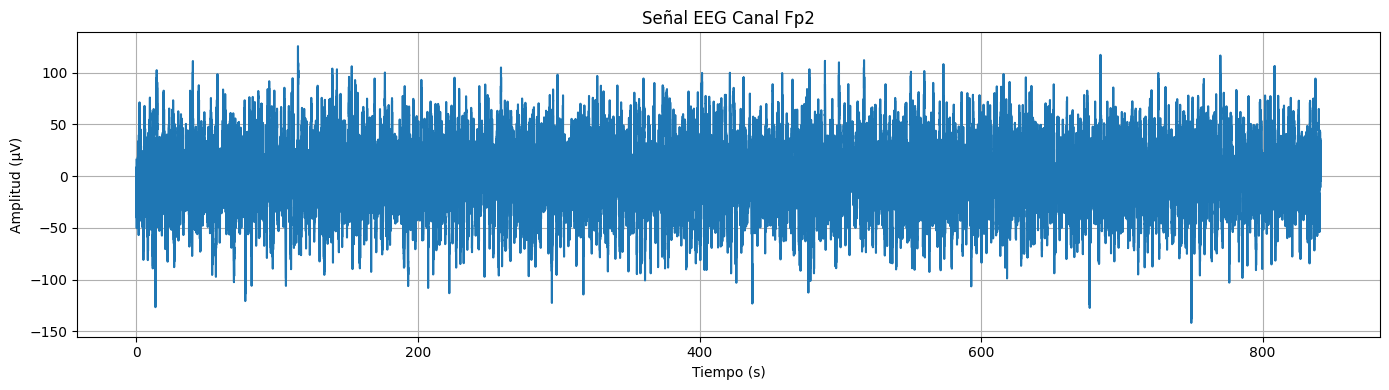

In [38]:
import matplotlib.pyplot as plt

# Seleccionar el canal
canal = "Fp2"

# Obtener la frecuencia de muestreo
sfreq = raw_set_eeg.info["sfreq"]
print(sfreq)
# Extraer los datos del canal seleccionado
senal = raw_set_eeg.get_data(picks=[canal])[0] * 1e6  # Convertir de V a µV

# Crear el eje de tiempo
tiempo = raw_set_eeg.times[:len(senal)]

# Graficar la señal EEG
plt.figure(figsize=(14, 4))
plt.plot(tiempo, senal)

plt.title(f"Señal EEG Canal {canal}")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (µV)")
plt.grid(True)
plt.tight_layout()
plt.show()

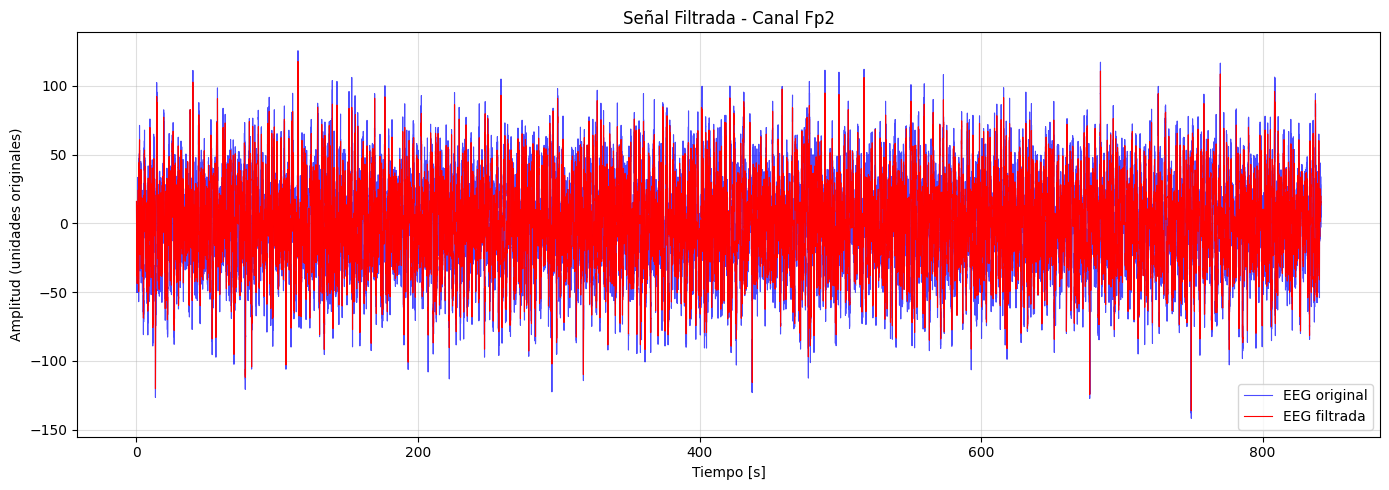

In [39]:
# aqui se muestra la señal 
from scipy import signal

lowcut = 10# Frecuencia de corte en Hz
orden = 4

# Verificar que la frecuencia de corte sea válida
if not 0 < lowcut < sfreq / 2:
    raise ValueError(
        "La frecuencia de corte debe estar entre 0 y Nyquist."
    )

# Diseñar el filtro Butterworth
sos = signal.butter(orden,lowcut, btype="lowpass", fs=sfreq, output="sos")

# Filtrar la señal original del segmento
x_filtrada = signal.sosfiltfilt(sos, senal)

plt.figure(figsize=(14, 5))
plt.plot(tiempo, senal, label="EEG original", alpha=0.7, linewidth=0.8, color='blue')
plt.plot(tiempo, x_filtrada, label="EEG filtrada", color='red',linewidth=0.8)
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud (unidades originales)")
plt.title(f"Señal Filtrada - Canal {canal}")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

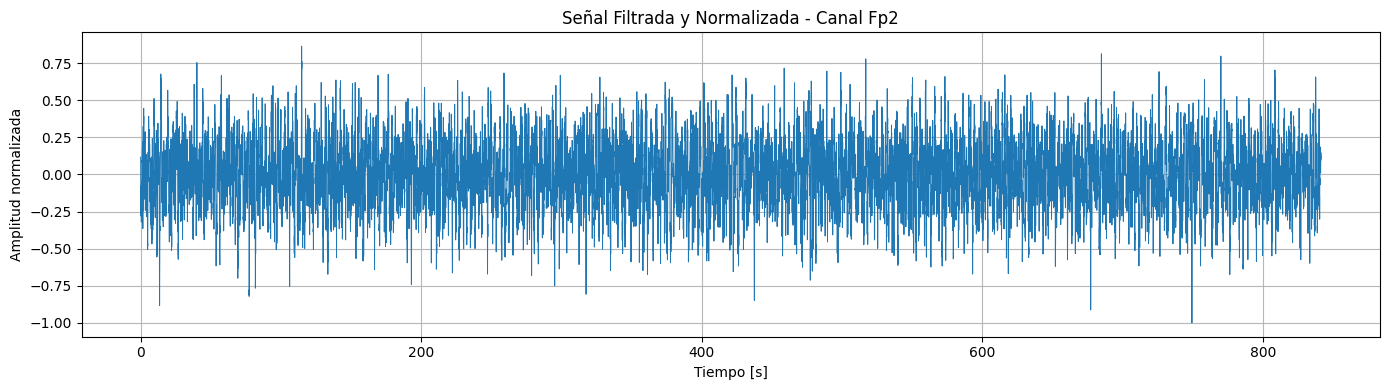

In [40]:
# se obtiene el valor absoluto de la señal para evitar valores negativos, es decir se encuentra normalizando la señal
max_abs = np.max(np.abs(x_filtrada))

if max_abs > 0:
    x_norm = x_filtrada / max_abs
else:
    x_norm = x_filtrada.copy()

# Eje temporal
t = np.arange(len(x_norm)) / sfreq

# Graficar señal filtrada y normalizada
plt.figure(figsize=(14, 4))
plt.plot(t, x_norm, linewidth=0.7)

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud normalizada")
plt.title(f"Señal Filtrada y Normalizada - Canal {canal}")
plt.grid(True, alpha=0.9)
plt.tight_layout()
plt.show()


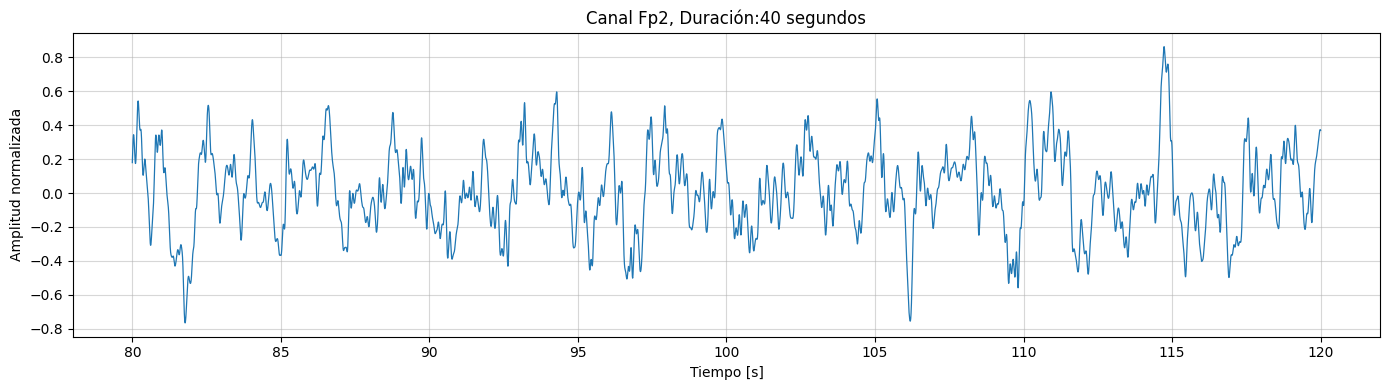

In [41]:
# estudiar  el inicio y el final de la señal, para ver si hay ruido o artefactos que puedan afectar el analisis de la señal se puede trabajar con 10 o 15 segundos, se esta graficando durante 20 segundos
# existen diferentes funciones
import numpy as np
import matplotlib.pyplot as plt

inicio = 80  # segundos
fin = 120    # segundos

# Convertir segundos a índices de muestras
muestra_inicio = int(inicio * sfreq)
muestra_fin = int(fin * sfreq)

# Extraer la señal
senal_ventana = x_norm[muestra_inicio:muestra_fin]

# Crear el eje temporal en segundos
t = np.arange(muestra_inicio, muestra_inicio + len(senal_ventana)) / sfreq

# Graficar la señal normalizada
plt.figure(figsize=(14, 4))
plt.plot(t, senal_ventana, linewidth=0.9)

plt.ylabel("Amplitud normalizada")
plt.xlabel("Tiempo [s]")
plt.title(f"Canal {canal}, Duración:{fin-inicio} segundos")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

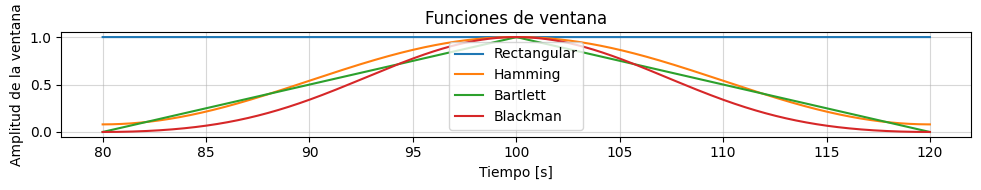

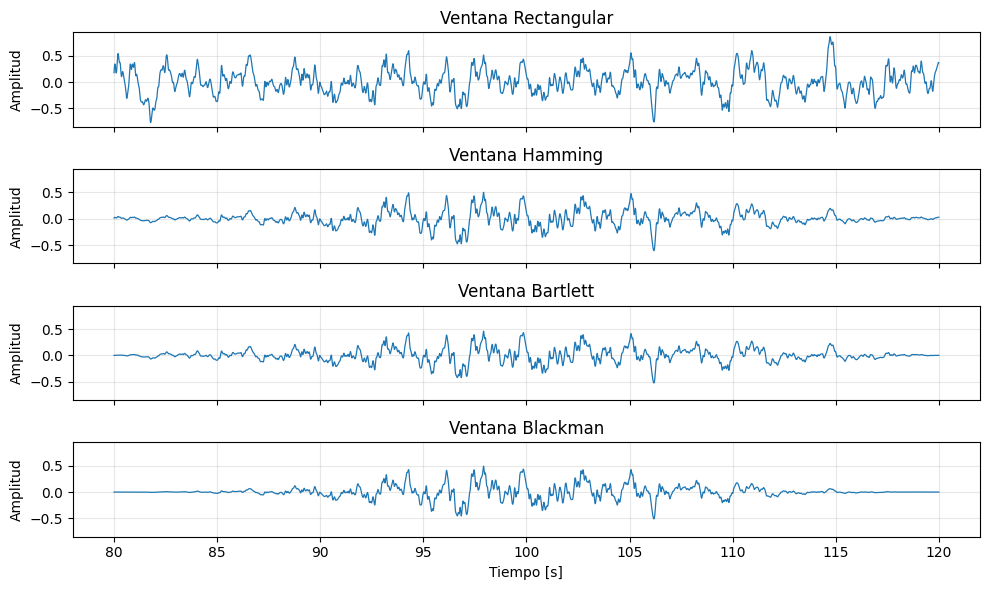

In [42]:
# funciones de ventana (ventaneo)
# ventana rectangular
# ventana de hamming
# ventana de bartlett
# ventana de blackman
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

N = len(senal_ventana)          # número de muestras del segmento
#t_v = np.arange(N) / sfreq      # eje temporal del segmento [s]

SYM = True   # True = simétrica (filtros) | False = periódica (FFT/espectro)

# ==========================================
# 1. Señal multiplicada por cada ventana
# ==========================================
x_rectangular = senal_ventana * windows.boxcar(N, sym=SYM)
x_hamming     = senal_ventana * windows.hamming(N, sym=SYM)
x_bartlett    = senal_ventana * windows.bartlett(N, sym=SYM)
x_blackman    = senal_ventana * windows.blackman(N, sym=SYM)

# ==========================================
# 2. Gráfica de las funciones de ventana
# ==========================================
plt.figure(figsize=(10, 2))
plt.plot(t, windows.boxcar(N, sym=SYM),   label="Rectangular")
plt.plot(t, windows.hamming(N, sym=SYM),  label="Hamming")
plt.plot(t, windows.bartlett(N, sym=SYM), label="Bartlett")
plt.plot(t, windows.blackman(N, sym=SYM), label="Blackman")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud de la ventana")
plt.title("Funciones de ventana")
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# 3. Gráfica de las cuatro señales
# ==========================================
fig, axes = plt.subplots(4, 1, figsize=(10, 6), sharex=True, sharey=True)

axes[0].plot(t, x_rectangular, linewidth=0.9)
axes[0].set_title("Ventana Rectangular")

axes[1].plot(t, x_hamming, linewidth=0.9)
axes[1].set_title("Ventana Hamming")

axes[2].plot(t, x_bartlett, linewidth=0.9)
axes[2].set_title("Ventana Bartlett")

axes[3].plot(t, x_blackman, linewidth=0.9)
axes[3].set_title("Ventana Blackman")

for ax in axes:
    ax.set_ylabel("Amplitud")
    ax.grid(True, alpha=0.3)

axes[3].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

In [43]:
# extraccion de caracteristicas de la señal (moda, media, mediana, desviacione estandar, varianza, etc), lo mas basico son las estadisticas y el analisis.... todo esta enfocado a lo que se quiere estudiar

# se va a calular la curtosis y la simetria (como se comporta nuestra grafica, puede tener un sesgo negativo, )
import scipy.io as sio
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

moda,_=stats.mode(x_rectangular,axis=None, keepdims=False)
mediana=np.median (x_rectangular)
media=np.mean (x_rectangular)

features1=[moda,mediana,media]

maximo= np.amax(x_rectangular)
minimo= np.amin (x_rectangular)
rango=maximo-minimo
desviación_estandar=np.std (x_rectangular)
varianza=np.var(x_rectangular)
features2=[maximo,minimo,rango,desviación_estandar,varianza]

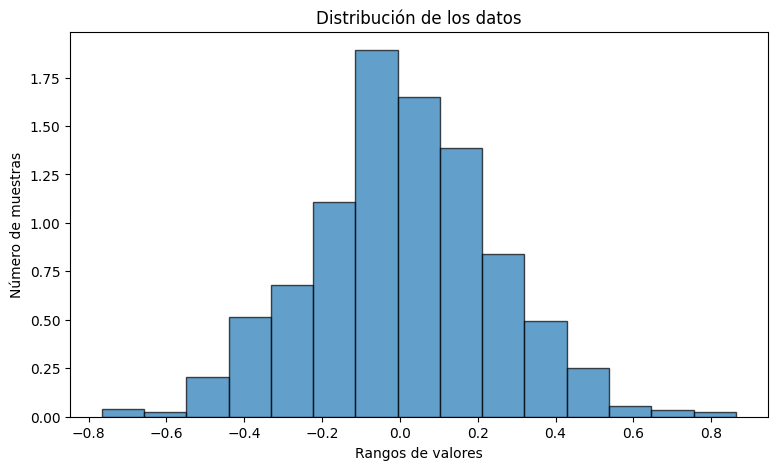

La simetria de esta señal es de 0.041711799432591054 y su curtosis es de : 0.2845051369886611


In [44]:
# se calculan los cuartiles, cientiles, quintiles, deciles
from scipy.stats import kurtosis
from scipy.stats import skew

#Observar la distribución de los datos de nuestra señal recortada con u histograma
plt.figure(figsize=(9, 5))
plt.hist(x_rectangular, bins=15, density=True, edgecolor="black", linewidth=1.0, alpha=0.7)
plt.ylabel('Número de muestras')
plt.xlabel('Rangos de valores')
plt.title('Distribución de los datos')
plt.show()

señal_filtrada_np=np.array(x_rectangular) #convertimos el dato a numpy

#curtosis
curtosis=kurtosis(señal_filtrada_np.T,axis=0, fisher=True)
#simetría
simetria=skew(señal_filtrada_np.T)
print(f'La simetria de esta señal es de ' + str(simetria) + ' y su curtosis es de : '+str( curtosis))

features3=[ simetria, curtosis ]

In [45]:
cruces=len(np.where(np.diff(np.sign(x_rectangular)))[0])

In [46]:
#Calcular el primer cuartil
q1 = np.percentile(x_rectangular, 25)
# Calcular el segundo cuartil
q2 = np.percentile(x_rectangular, 50)
# Calcular el tercer cuartil (
q3 = np.percentile(x_rectangular, 75)

# Imprimir los resultados
print(f'Primer cuartil : {q1}')
print(f'Segundo cuartil (Mediana): {q2}')
print(f'Tercer cuartil: {q3}')
features4=[q1, q2, q3]

Primer cuartil : -0.1414982520791827
Segundo cuartil (Mediana): 0.000818602146643737
Tercer cuartil: 0.1588417262977629


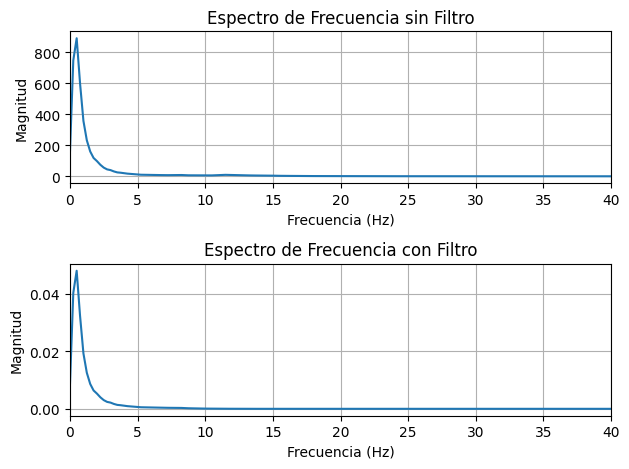

In [47]:
# caracterizacion en el dominio de la frecuencia <- ritmo del tiempo
# Grafica el espectro de frecuencia
plt.figure()
frequencies, power_spectrum = signal.welch(senal,sfreq,nperseg=int(4*sfreq))
frequencies_sf, power_spectrum_sf = signal.welch(x_norm,sfreq,nperseg=int(4*sfreq))

plt.subplot(2, 1, 1)
plt.plot(frequencies, power_spectrum)
plt.title('Espectro de Frecuencia sin Filtro')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud')
plt.xlim(0,40)
plt.grid()

#Señal con filtro
plt.subplot(2, 1, 2)
plt.plot(frequencies_sf, power_spectrum_sf.T)
plt.title('Espectro de Frecuencia con Filtro')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud')
plt.xlim(0,40)
plt.grid()

plt.tight_layout()
plt.show()

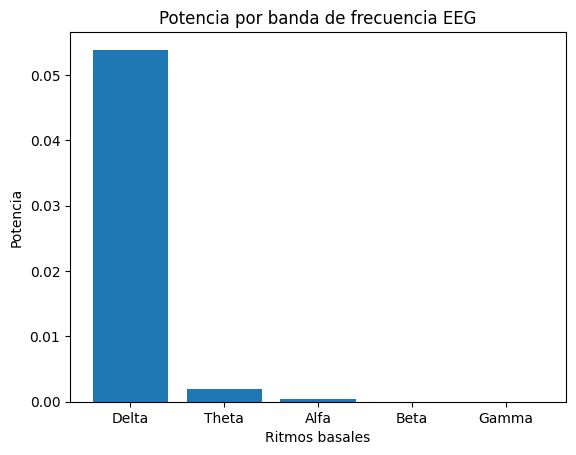

Frecuencia dominante: 0.525 Hz


In [48]:
# Gamma (es la banda mas rapida) 32 - 100 Hz
# Beta 13 - 32 Hz
# Alfa 8 - 13 Hz
# Theta 4 - 8 Hz
# Delta (es la banada mas lenta) 0.5 - 4 Hz
frequencies, power_spectrum = signal.periodogram(x_rectangular, fs=sfreq)

bandas = {
    'Delta': (0.1, 4),
    'Theta': (4, 8),
    'Alfa': (8, 13),
    'Beta': (13, 30),
    'Gamma': (30, 45)
}

ritmos = []
potencias = []

for ritmo, (f_min, f_max) in bandas.items():
    indices = (frequencies >= f_min) & (frequencies < f_max)

    potencia = np.trapezoid(power_spectrum[indices], frequencies[indices])

    ritmos.append(ritmo)
    potencias.append(potencia)

plt.bar(ritmos, potencias)
plt.xlabel('Ritmos basales')
plt.ylabel('Potencia')
plt.title('Potencia por banda de frecuencia EEG')
plt.show()

# Frecuencia dominante dentro del rango de interés
indices = (frequencies >= 0.1) & (frequencies <= 45)

frecuencia_dominante = frequencies[indices][
    np.argmax(power_spectrum[indices])
]

print("Frecuencia dominante:", frecuencia_dominante, "Hz")

In [49]:
# Se muestran dos graficas (la misma grafica pero con diferentes amplitudes)

In [50]:
# En este segmento la frecuencia que predomina es la delta, tambien existen del dominio tiempo - frecuencia, fragtal
import pandas as pd
Valores=[canal,moda, mediana, media, maximo, minimo, rango, desviación_estandar, varianza, float(simetria), float(curtosis), cruces,q1,q2,q3, frecuencia_dominante]
parametros=['Canal','Moda', 'Mediana',' Media', 'Máximo', 'Mínimo', 'Rango', 'Desviación estandar', 'Varianza', 'Simetria', 'Curtosis', 'Cruces por cero','Cuantil 1','Cuantil 2', 'Cuantil 3','Frecuencia dominante']
Para_esta = pd.DataFrame(list(zip(parametros,Valores)), columns = ['Parametros','Registro'])
Para_esta

,Parametros,Registro
0,Canal,Fp2
1,Moda,-0.766173
2,Mediana,0.000819
3,Media,0.008171
4,Máximo,0.863392
5,Mínimo,-0.766173
6,Rango,1.629565
7,Desviación estandar,0.237476
8,Varianza,0.056395
9,Simetria,0.041712



SVM
              precision    recall  f1-score   support

          HC      0.737     0.483     0.583        29
          AD      0.674     0.861     0.756        36

    accuracy                          0.692        65
   macro avg      0.705     0.672     0.670        65
weighted avg      0.702     0.692     0.679        65


RF
              precision    recall  f1-score   support

          HC      0.615     0.552     0.582        29
          AD      0.667     0.722     0.693        36

    accuracy                          0.646        65
   macro avg      0.641     0.637     0.638        65
weighted avg      0.644     0.646     0.644        65



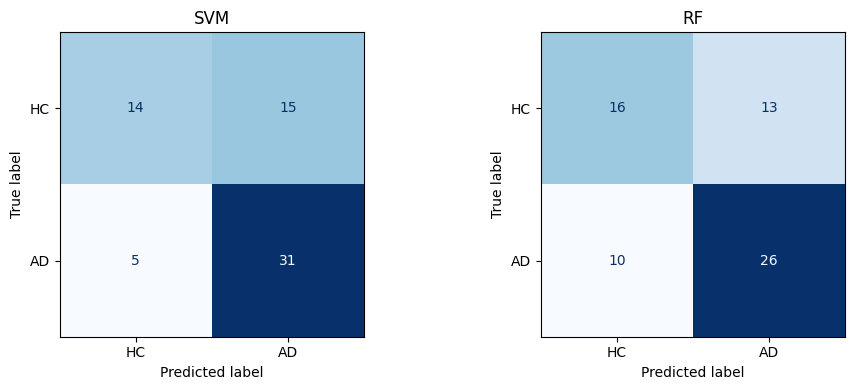

In [51]:
# antes de la clasificacion concatenar todas las caracteristicas obtenidas, solo hay 14 carac. se pueden llegar hasta 100 - 200 caract. por canales, se calcula el promedio y la desviacion estandar

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ==========================================
# 1. Cargar datos
# ==========================================
df = pd.read_csv('./Features_EEG_HC_AD_ancho.csv')
X = df.drop(columns=['sujeto', 'archivo', 'clase', 'sfreq', 'duracion_seg'])
y = df['clase'].map({'HC': 0, 'AD': 1})

etiquetas = ['HC', 'AD']
# ==========================================
# 2. Modelos y validación cruzada
# ==========================================
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

modelos = {'SVM': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', C=1.0, gamma='scale'))]),
            'RF': RandomForestClassifier( n_estimators=300, random_state=42)}
# ==========================================
# 3. Reporte y matrices de confusión
# ==========================================
fig, axes = plt.subplots(1, len(modelos), figsize=(10, 4))

for ax, (nombre, modelo) in zip(axes, modelos.items()):

    # Predicciones mediante validación cruzada
    y_pred = cross_val_predict(modelo, X, y, cv=cv)

    # Reporte generado por scikit-learn
    print(f'\n{"=" * 45}')
    print(nombre)
    print('=' * 45)
    print(classification_report(y, y_pred, labels=[0, 1], target_names=etiquetas, digits=3))

    # Matriz de confusión
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay( confusion_matrix=cm, display_labels=etiquetas).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre)

plt.tight_layout()
plt.savefig('matrices_confusion.png', dpi=150)
plt.show()

CON EL ARCHIVO EDF

In [58]:
def consultar_info(raw, nombre):
    print(f"\n{'=' * 40}")
    print(f"INFORMACIÓN DEL ARCHIVO: {nombre}")
    print(f"{'=' * 40}")

    print(f"Número de canales: {len(raw.ch_names)}")
    print(f"Frecuencia de muestreo: {raw.info['sfreq']} Hz")
    print(f"Número de muestras: {raw.n_times}")
    print(f"Duración: {raw.n_times / raw.info['sfreq']:.2f} segundos")
    print(f"Nombres de los canales: {raw.ch_names}")
    print(f"Fecha de medición: {raw.info['meas_date']}")

    print("\nInformación detallada:")
    print(raw.info)

consultar_info(raw_edf, "EDF")


INFORMACIÓN DEL ARCHIVO: EDF
Número de canales: 30
Frecuencia de muestreo: 1024.0 Hz
Número de muestras: 308224
Duración: 301.00 segundos
Nombres de los canales: ['Fp1', 'F7', 'F8', 'T4', 'T6', 'T5', 'T3', 'Fp2', 'O1', 'P3', 'Pz', 'F3', 'Fz', 'F4', 'C4', 'P4', 'POz', 'C3', 'Cz', 'O2', 'ECG', 'AUX1', 'AUX2', 'AUX3', 'ESUTimestamp', 'SystemTimestamp', 'Battery', 'Tilt X', 'Tilt Y', 'Tilt Z']
Fecha de medición: 2017-03-14 10:37:30+00:00

Información detallada:
<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, F7, F8, T4, T6, T5, T3, Fp2, O1, P3, Pz, F3, Fz, F4, C4, ...
 chs: 30 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 512.0 Hz
 meas_date: 2017-03-14 10:37:30 UTC
 nchan: 30
 projs: []
 sfreq: 1024.0 Hz
 subject_info: <subject_info | his_id: XXXXSession, sex: 0, last_name: 0>
>


1024.0


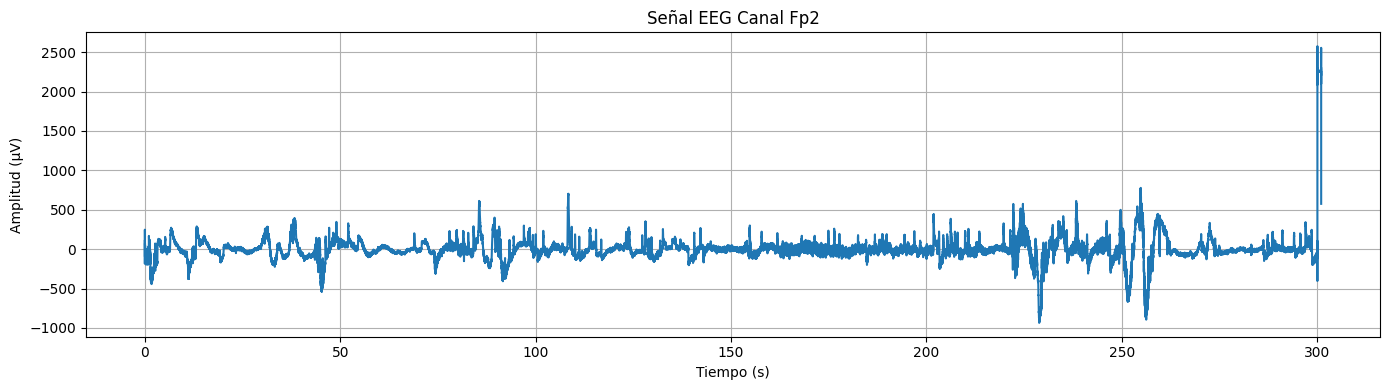

In [52]:
# CON EL ARCHIVO EDF
# raw_edf

import matplotlib.pyplot as plt

# Seleccionar el canal
canal = "Fp2"

# Obtener la frecuencia de muestreo
sfreq = raw_edf_eeg.info["sfreq"]
print(sfreq)
# Extraer los datos del canal seleccionado
senal = raw_edf_eeg.get_data(picks=[canal])[0] * 1e6  # Convertir de V a µV

# Crear el eje de tiempo
tiempo = raw_edf_eeg.times[:len(senal)]

# Graficar la señal EEG
plt.figure(figsize=(14, 4))
plt.plot(tiempo, senal)

plt.title(f"Señal EEG Canal {canal}")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (µV)")
plt.grid(True)
plt.tight_layout()
plt.show()


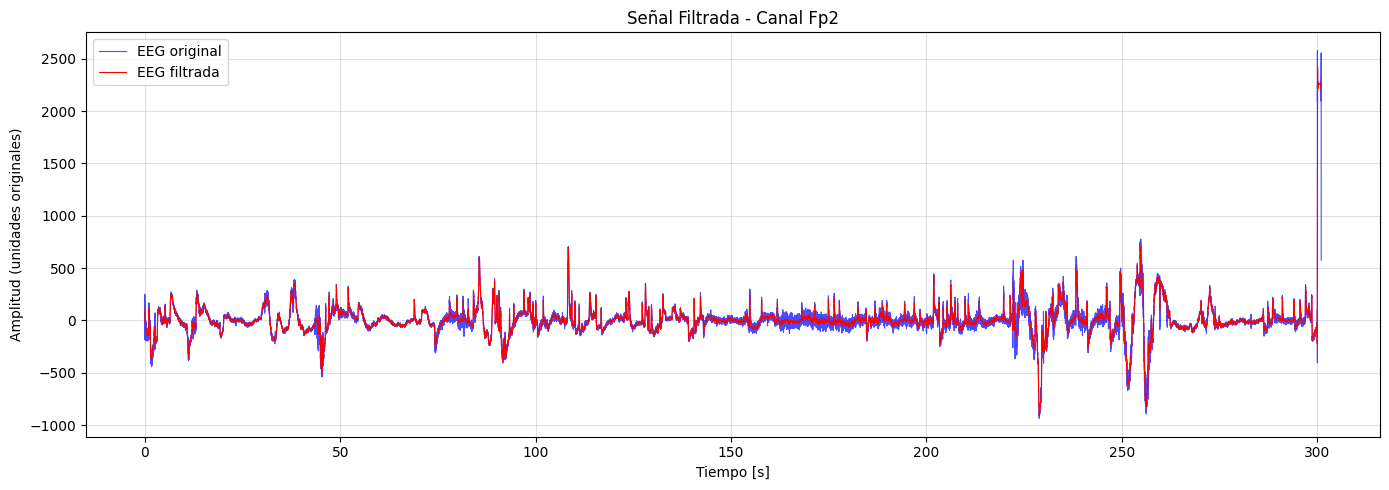

In [53]:
# aqui se muestra la señal 
from scipy import signal

lowcut = 10# Frecuencia de corte en Hz
orden = 4

# Verificar que la frecuencia de corte sea válida
if not 0 < lowcut < sfreq / 2:
    raise ValueError(
        "La frecuencia de corte debe estar entre 0 y Nyquist."
    )

# Diseñar el filtro Butterworth
sos = signal.butter(orden,lowcut, btype="lowpass", fs=sfreq, output="sos")

# Filtrar la señal original del segmento
x_filtrada = signal.sosfiltfilt(sos, senal)

plt.figure(figsize=(14, 5))
plt.plot(tiempo, senal, label="EEG original", alpha=0.7, linewidth=0.8, color='blue')
plt.plot(tiempo, x_filtrada, label="EEG filtrada", color='red',linewidth=0.8)
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud (unidades originales)")
plt.title(f"Señal Filtrada - Canal {canal}")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

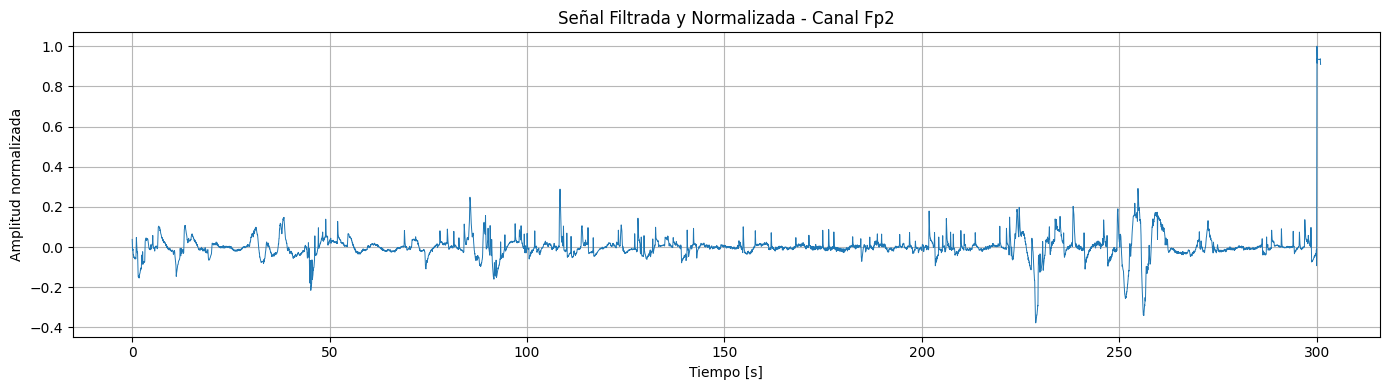

In [54]:
# se obtiene el valor absoluto de la señal para evitar valores negativos, es decir se encuentra normalizando la señal
max_abs = np.max(np.abs(x_filtrada))

if max_abs > 0:
    x_norm = x_filtrada / max_abs
else:
    x_norm = x_filtrada.copy()

# Eje temporal
t = np.arange(len(x_norm)) / sfreq

# Graficar señal filtrada y normalizada
plt.figure(figsize=(14, 4))
plt.plot(t, x_norm, linewidth=0.7)

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud normalizada")
plt.title(f"Señal Filtrada y Normalizada - Canal {canal}")
plt.grid(True, alpha=0.9)
plt.tight_layout()
plt.show()


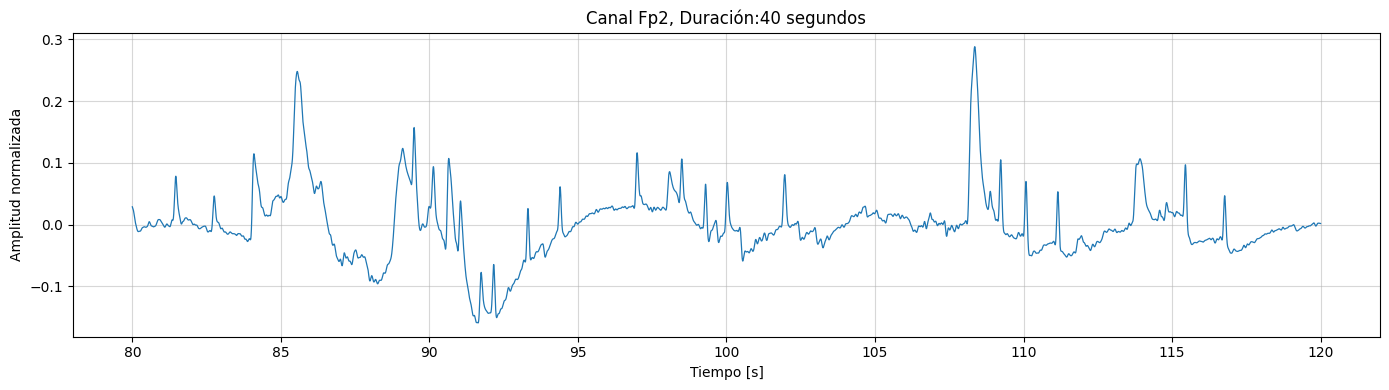

In [55]:
# estudiar  el inicio y el final de la señal, para ver si hay ruido o artefactos que puedan afectar el analisis de la señal se puede trabajar con 10 o 15 segundos, se esta graficando durante 20 segundos
# existen diferentes funciones
import numpy as np
import matplotlib.pyplot as plt

inicio = 80  # segundos
fin = 120    # segundos

# Convertir segundos a índices de muestras
muestra_inicio = int(inicio * sfreq)
muestra_fin = int(fin * sfreq)

# Extraer la señal
senal_ventana = x_norm[muestra_inicio:muestra_fin]

# Crear el eje temporal en segundos
t = np.arange(muestra_inicio, muestra_inicio + len(senal_ventana)) / sfreq

# Graficar la señal normalizada
plt.figure(figsize=(14, 4))
plt.plot(t, senal_ventana, linewidth=0.9)

plt.ylabel("Amplitud normalizada")
plt.xlabel("Tiempo [s]")
plt.title(f"Canal {canal}, Duración:{fin-inicio} segundos")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

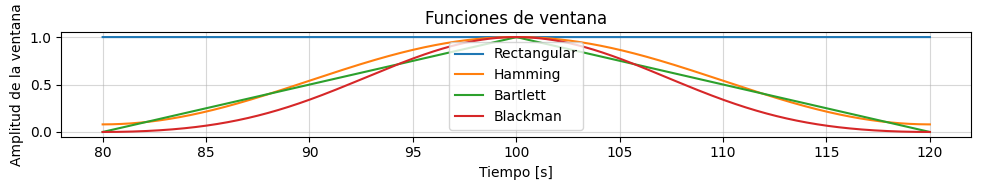

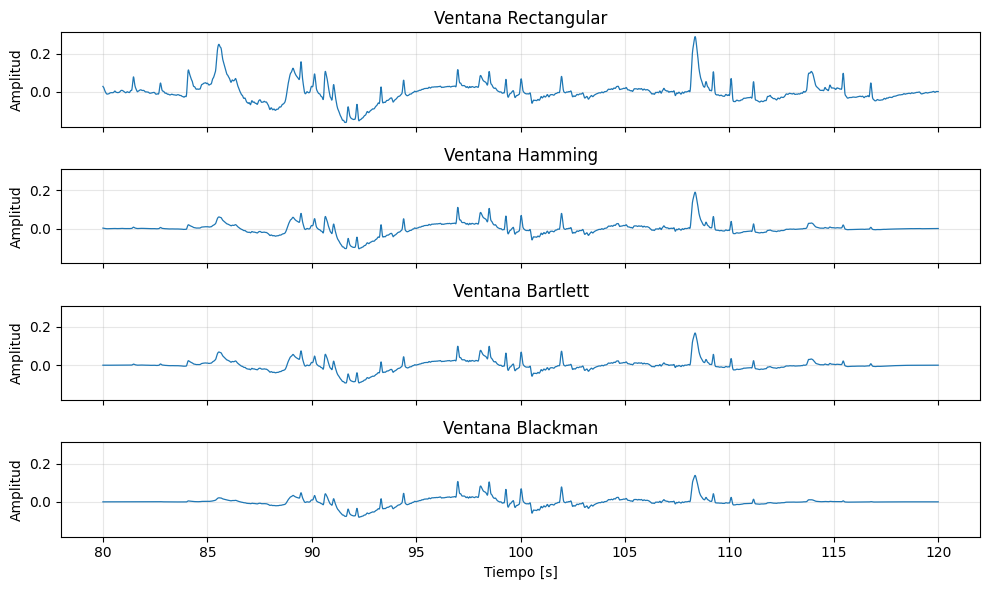

In [56]:
# funciones de ventana (ventaneo)
# ventana rectangular
# ventana de hamming
# ventana de bartlett
# ventana de blackman
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

N = len(senal_ventana)          # número de muestras del segmento
#t_v = np.arange(N) / sfreq      # eje temporal del segmento [s]

SYM = True   # True = simétrica (filtros) | False = periódica (FFT/espectro)

# ==========================================
# 1. Señal multiplicada por cada ventana
# ==========================================
x_rectangular = senal_ventana * windows.boxcar(N, sym=SYM)
x_hamming     = senal_ventana * windows.hamming(N, sym=SYM)
x_bartlett    = senal_ventana * windows.bartlett(N, sym=SYM)
x_blackman    = senal_ventana * windows.blackman(N, sym=SYM)

# ==========================================
# 2. Gráfica de las funciones de ventana
# ==========================================
plt.figure(figsize=(10, 2))
plt.plot(t, windows.boxcar(N, sym=SYM),   label="Rectangular")
plt.plot(t, windows.hamming(N, sym=SYM),  label="Hamming")
plt.plot(t, windows.bartlett(N, sym=SYM), label="Bartlett")
plt.plot(t, windows.blackman(N, sym=SYM), label="Blackman")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud de la ventana")
plt.title("Funciones de ventana")
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# 3. Gráfica de las cuatro señales
# ==========================================
fig, axes = plt.subplots(4, 1, figsize=(10, 6), sharex=True, sharey=True)

axes[0].plot(t, x_rectangular, linewidth=0.9)
axes[0].set_title("Ventana Rectangular")

axes[1].plot(t, x_hamming, linewidth=0.9)
axes[1].set_title("Ventana Hamming")

axes[2].plot(t, x_bartlett, linewidth=0.9)
axes[2].set_title("Ventana Bartlett")

axes[3].plot(t, x_blackman, linewidth=0.9)
axes[3].set_title("Ventana Blackman")

for ax in axes:
    ax.set_ylabel("Amplitud")
    ax.grid(True, alpha=0.3)

axes[3].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

In [59]:
# extraccion de caracteristicas de la señal (moda, media, mediana, desviacione estandar, varianza, etc), lo mas basico son las estadisticas y el analisis.... todo esta enfocado a lo que se quiere estudiar

# se va a calular la curtosis y la simetria (como se comporta nuestra grafica, puede tener un sesgo negativo, )
import scipy.io as sio
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

moda,_=stats.mode(x_rectangular,axis=None, keepdims=False)
mediana=np.median (x_rectangular)
media=np.mean (x_rectangular)

features1=[moda,mediana,media]

maximo= np.amax(x_rectangular)
minimo= np.amin (x_rectangular)
rango=maximo-minimo
desviación_estandar=np.std (x_rectangular)
varianza=np.var(x_rectangular)
features2=[maximo,minimo,rango,desviación_estandar,varianza]

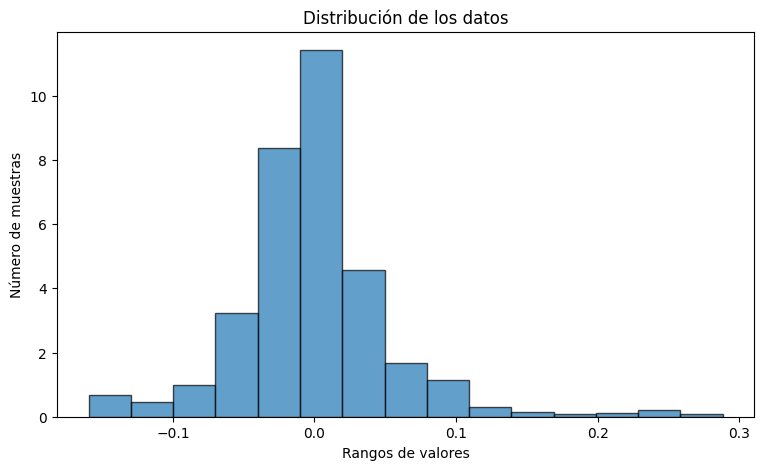

La simetria de esta señal es de 1.0221232441891586 y su curtosis es de : 5.135340370659161


In [60]:
# se calculan los cuartiles, cientiles, quintiles, deciles
from scipy.stats import kurtosis
from scipy.stats import skew

#Observar la distribución de los datos de nuestra señal recortada con u histograma
plt.figure(figsize=(9, 5))
plt.hist(x_rectangular, bins=15, density=True, edgecolor="black", linewidth=1.0, alpha=0.7)
plt.ylabel('Número de muestras')
plt.xlabel('Rangos de valores')
plt.title('Distribución de los datos')
plt.show()

señal_filtrada_np=np.array(x_rectangular) #convertimos el dato a numpy

#curtosis
curtosis=kurtosis(señal_filtrada_np.T,axis=0, fisher=True)
#simetría
simetria=skew(señal_filtrada_np.T)
print(f'La simetria de esta señal es de ' + str(simetria) + ' y su curtosis es de : '+str( curtosis))

features3=[ simetria, curtosis ]

In [61]:
cruces=len(np.where(np.diff(np.sign(x_rectangular)))[0])

In [62]:
#Calcular el primer cuartil
q1 = np.percentile(x_rectangular, 25)
# Calcular el segundo cuartil
q2 = np.percentile(x_rectangular, 50)
# Calcular el tercer cuartil (
q3 = np.percentile(x_rectangular, 75)

# Imprimir los resultados
print(f'Primer cuartil : {q1}')
print(f'Segundo cuartil (Mediana): {q2}')
print(f'Tercer cuartil: {q3}')
features4=[q1, q2, q3]

Primer cuartil : -0.02520933069407323
Segundo cuartil (Mediana): -0.003893122632243344
Tercer cuartil: 0.01947491838421679


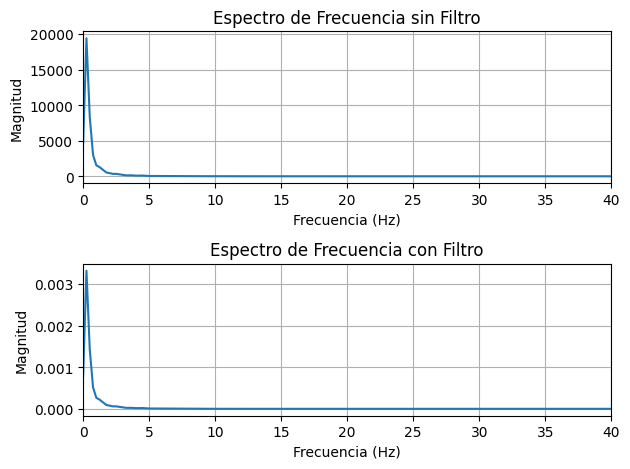

In [63]:
# caracterizacion en el dominio de la frecuencia <- ritmo del tiempo
# Grafica el espectro de frecuencia
plt.figure()
frequencies, power_spectrum = signal.welch(senal,sfreq,nperseg=int(4*sfreq))
frequencies_sf, power_spectrum_sf = signal.welch(x_norm,sfreq,nperseg=int(4*sfreq))

plt.subplot(2, 1, 1)
plt.plot(frequencies, power_spectrum)
plt.title('Espectro de Frecuencia sin Filtro')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud')
plt.xlim(0,40)
plt.grid()

#Señal con filtro
plt.subplot(2, 1, 2)
plt.plot(frequencies_sf, power_spectrum_sf.T)
plt.title('Espectro de Frecuencia con Filtro')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Magnitud')
plt.xlim(0,40)
plt.grid()

plt.tight_layout()
plt.show()

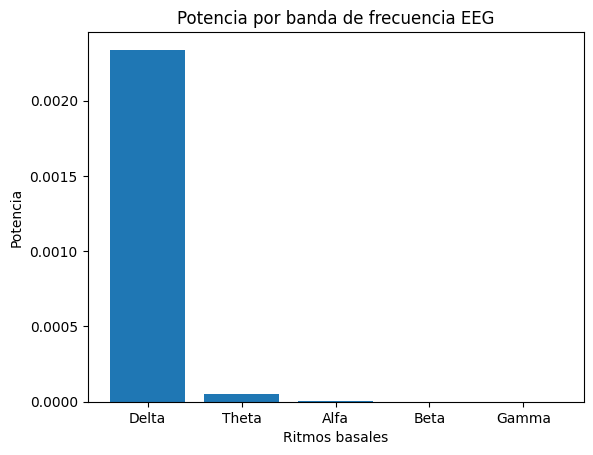

Frecuencia dominante: 0.17500000000000002 Hz


In [64]:
# Gamma (es la banda mas rapida) 32 - 100 Hz
# Beta 13 - 32 Hz
# Alfa 8 - 13 Hz
# Theta 4 - 8 Hz
# Delta (es la banada mas lenta) 0.5 - 4 Hz
frequencies, power_spectrum = signal.periodogram(x_rectangular, fs=sfreq)

bandas = {
    'Delta': (0.1, 4),
    'Theta': (4, 8),
    'Alfa': (8, 13),
    'Beta': (13, 30),
    'Gamma': (30, 45)
}

ritmos = []
potencias = []

for ritmo, (f_min, f_max) in bandas.items():
    indices = (frequencies >= f_min) & (frequencies < f_max)

    potencia = np.trapezoid(power_spectrum[indices], frequencies[indices])

    ritmos.append(ritmo)
    potencias.append(potencia)

plt.bar(ritmos, potencias)
plt.xlabel('Ritmos basales')
plt.ylabel('Potencia')
plt.title('Potencia por banda de frecuencia EEG')
plt.show()

# Frecuencia dominante dentro del rango de interés
indices = (frequencies >= 0.1) & (frequencies <= 45)

frecuencia_dominante = frequencies[indices][
    np.argmax(power_spectrum[indices])
]

print("Frecuencia dominante:", frecuencia_dominante, "Hz")

In [65]:
# En este segmento la frecuencia que predomina es la delta, tambien existen del dominio tiempo - frecuencia, fragtal
import pandas as pd
Valores=[canal,moda, mediana, media, maximo, minimo, rango, desviación_estandar, varianza, float(simetria), float(curtosis), cruces,q1,q2,q3, frecuencia_dominante]
parametros=['Canal','Moda', 'Mediana',' Media', 'Máximo', 'Mínimo', 'Rango', 'Desviación estandar', 'Varianza', 'Simetria', 'Curtosis', 'Cruces por cero','Cuantil 1','Cuantil 2', 'Cuantil 3','Frecuencia dominante']
Para_esta = pd.DataFrame(list(zip(parametros,Valores)), columns = ['Parametros','Registro'])
Para_esta

,Parametros,Registro
0,Canal,Fp2
1,Moda,-0.159535
2,Mediana,-0.003893
3,Media,-0.000682
4,Máximo,0.288395
5,Mínimo,-0.159535
6,Rango,0.44793
7,Desviación estandar,0.054026
8,Varianza,0.002919
9,Simetria,1.022123



SVM
              precision    recall  f1-score   support

          HC      0.737     0.483     0.583        29
          AD      0.674     0.861     0.756        36

    accuracy                          0.692        65
   macro avg      0.705     0.672     0.670        65
weighted avg      0.702     0.692     0.679        65


RF
              precision    recall  f1-score   support

          HC      0.615     0.552     0.582        29
          AD      0.667     0.722     0.693        36

    accuracy                          0.646        65
   macro avg      0.641     0.637     0.638        65
weighted avg      0.644     0.646     0.644        65



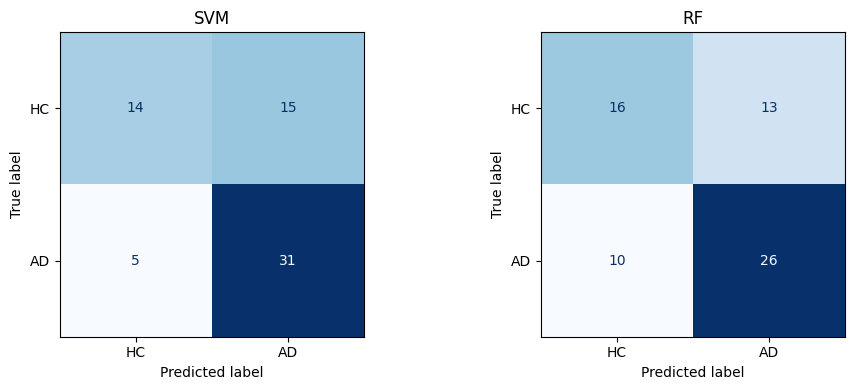

In [66]:
# antes de la clasificacion concatenar todas las caracteristicas obtenidas, solo hay 14 carac. se pueden llegar hasta 100 - 200 caract. por canales, se calcula el promedio y la desviacion estandar

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ==========================================
# 1. Cargar datos
# ==========================================
df = pd.read_csv('./Features_EEG_HC_AD_ancho.csv')
X = df.drop(columns=['sujeto', 'archivo', 'clase', 'sfreq', 'duracion_seg'])
y = df['clase'].map({'HC': 0, 'AD': 1})

etiquetas = ['HC', 'AD']
# ==========================================
# 2. Modelos y validación cruzada
# ==========================================
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

modelos = {'SVM': Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', C=1.0, gamma='scale'))]),
            'RF': RandomForestClassifier( n_estimators=300, random_state=42)}
# ==========================================
# 3. Reporte y matrices de confusión
# ==========================================
fig, axes = plt.subplots(1, len(modelos), figsize=(10, 4))

for ax, (nombre, modelo) in zip(axes, modelos.items()):

    # Predicciones mediante validación cruzada
    y_pred = cross_val_predict(modelo, X, y, cv=cv)

    # Reporte generado por scikit-learn
    print(f'\n{"=" * 45}')
    print(nombre)
    print('=' * 45)
    print(classification_report(y, y_pred, labels=[0, 1], target_names=etiquetas, digits=3))

    # Matriz de confusión
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay( confusion_matrix=cm, display_labels=etiquetas).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre)

plt.tight_layout()
plt.savefig('matrices_confusion.png', dpi=150)
plt.show()

CONSULTAR LA INFORMACION DE LAS BASES DE DATOS - CALSFICACION SUPERVISADA